# Результаты HW5

Ноутбук читает сохранённые BFCL-оценки и логи обучения.
Ноутбук не загружает модель и не занимает GPU.

Источники:

- `artifacts/<run>/metrics.json` — BFCL
- `artifacts/<run>/predictions.jsonl` — ответы и проверки
- `results/<run>/history.json` — награда и loss по шагам
- `results/<run>/summary.json` и `config.json` — условия запуска


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path(".").resolve()
RUNS = ["baseline", "rl_exact", "rl_shaped", "rl_lr"]
TRAIN_RUNS = ["rl_exact", "rl_shaped", "rl_lr"]
GROUPS = ["simple", "multiple", "parallel", "parallel_multiple", "irrelevance"]
GROUP_LABELS = ["Simple", "Multiple", "Parallel", "Parallel + Multiple", "Irrelevance"]
COLORS = {
    "baseline": "#4C566A",
    "rl_exact": "#5E81AC",
    "rl_shaped": "#A3BE8C",
    "rl_lr": "#B48EAD",
}

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "figure.dpi": 120,
})
PLOTS = ROOT / "plots"
PLOTS.mkdir(exist_ok=True)


def read_json(path):
    return json.loads(Path(path).read_text())


def training_steps(name):
    rows = read_json(ROOT / "results" / name / "history.json")
    return [row for row in rows if "reward" in row]


## BFCL

`overall` — среднее пяти групп.
`overall` не равен доле верных ответов среди 350 примеров.
`Multiple` объединяет `multiple` и `live_multiple`.
`Irrelevance` объединяет `irrelevance` и `live_irrelevance`.


In [2]:
bfcl_rows = []
for name in RUNS:
    metrics = read_json(ROOT / "artifacts" / name / "metrics.json")
    row = {"run": name, "overall": metrics["overall"]}
    row.update({group: metrics["groups"][group] for group in GROUPS})
    bfcl_rows.append(row)

bfcl = pd.DataFrame(bfcl_rows).set_index("run")
bfcl = bfcl[["overall", *GROUPS]]
percent = (bfcl * 100).round(2)
percent.insert(1, "delta_pp", (percent["overall"] - percent.loc["baseline", "overall"]).round(2))
percent.to_csv(ROOT / "artifacts" / "comparison.csv")
percent


,overall,delta_pp,simple,multiple,parallel,parallel_multiple,irrelevance
run,,,,,,,
baseline,68.93,0.00,68.0,78.67,56.0,80.0,62.0
rl_exact,68.67,-0.26,66.0,79.33,56.0,80.0,62.0
rl_shaped,68.93,0.00,70.0,80.67,56.0,80.0,58.0
rl_lr,69.87,0.94,70.0,81.33,58.0,80.0,60.0


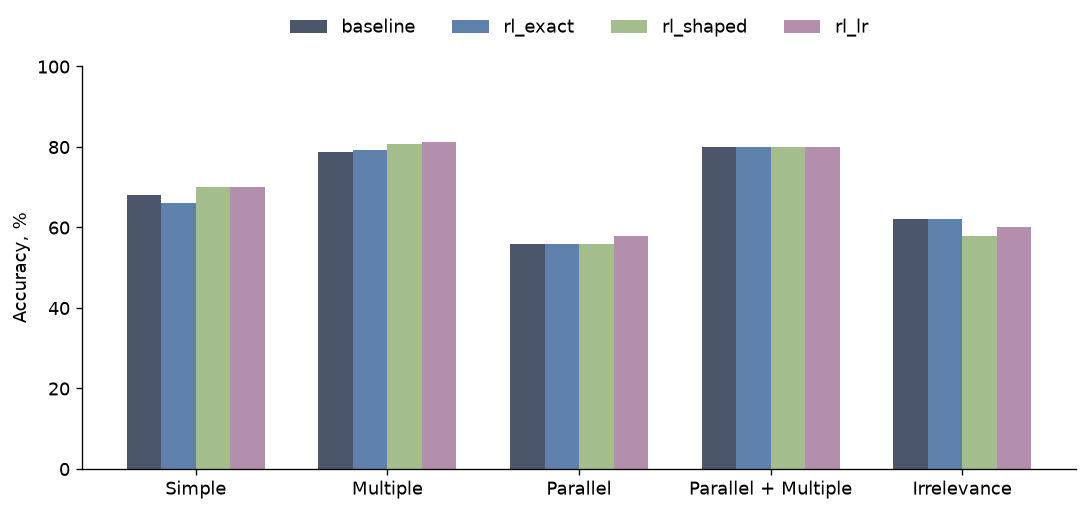

In [3]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
positions = list(range(len(GROUPS)))
width = 0.18
for index, name in enumerate(RUNS):
    offset = (index - 1.5) * width
    values = [bfcl.loc[name, group] * 100 for group in GROUPS]
    ax.bar(
        [pos + offset for pos in positions],
        values,
        width=width,
        label=name,
        color=COLORS[name],
    )
ax.set_xticks(positions)
ax.set_xticklabels(GROUP_LABELS)
ax.set_ylabel("Accuracy, %")
ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.16))
fig.tight_layout()
fig.savefig(PLOTS / "bfcl.png", dpi=160, bbox_inches="tight")
plt.show()


## Сравнение качества

`overall` — среднее пяти групп BFCL.
`accuracy` — доля верных ответов среди 350 примеров.
Ниже оба числа и разница с baseline.


In [4]:
quality_rows = []
for name in RUNS:
    metrics = read_json(ROOT / "artifacts" / name / "metrics.json")
    correct = sum(item["correct"] for item in metrics["categories"].values())
    total = sum(item["total"] for item in metrics["categories"].values())
    quality_rows.append({
        "run": name,
        "overall_%": round(metrics["overall"] * 100, 2),
        "accuracy_%": round(correct / total * 100, 2),
        "correct": correct,
        "total": total,
    })

quality = pd.DataFrame(quality_rows).set_index("run")
base_overall = quality.loc["baseline", "overall_%"]
base_correct = quality.loc["baseline", "correct"]
quality["delta_overall_pp"] = (quality["overall_%"] - base_overall).round(2)
quality["delta_correct"] = quality["correct"] - base_correct
quality = quality.sort_values(["accuracy_%", "overall_%"], ascending=False)
quality.to_csv(ROOT / "artifacts" / "quality.csv")

best = quality.index[0]
print(f"Лучший запуск по accuracy: {best}")
print(f"Верных ответов: {int(quality.loc[best, 'correct'])} из {int(quality.loc[best, 'total'])}")
print(f"Разница с baseline: {int(quality.loc[best, 'delta_correct']):+d} ответов, {quality.loc[best, 'delta_overall_pp']:+.2f} п.п. overall")
quality


Лучший запуск по accuracy: rl_lr
Верных ответов: 256 из 350
Разница с baseline: +5 ответов, +0.94 п.п. overall


,overall_%,accuracy_%,correct,total,delta_overall_pp,delta_correct
run,,,,,,
rl_lr,69.87,73.14,256,350,0.94,5
rl_shaped,68.93,72.29,253,350,0.00,2
baseline,68.93,71.71,251,350,0.00,0
rl_exact,68.67,71.71,251,350,-0.26,0


## Обучение

Линия — средняя награда или loss за 10 шагов.
Награды `rl_exact` и двух shaped-запусков имеют разный масштаб.


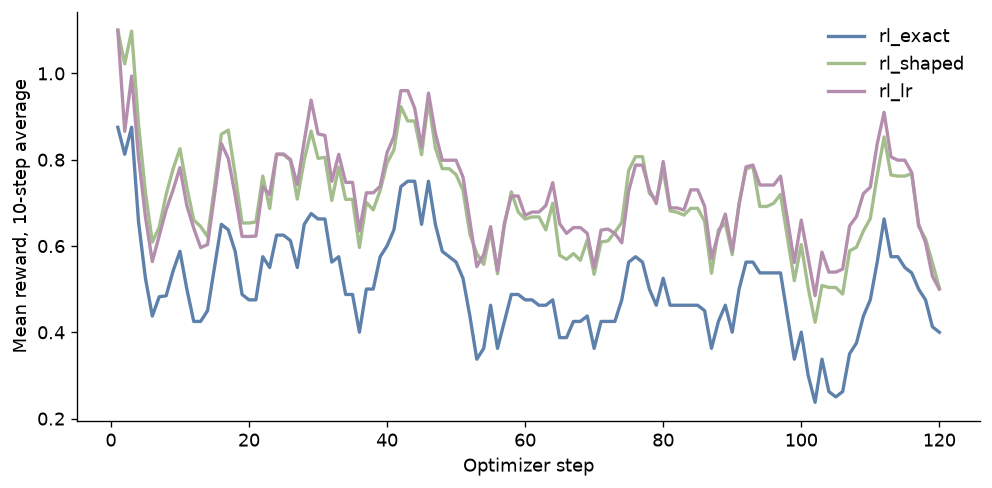

In [5]:
histories = {name: training_steps(name) for name in TRAIN_RUNS}

fig, ax = plt.subplots(figsize=(8.4, 4.2))
for name in TRAIN_RUNS:
    frame = pd.DataFrame(histories[name])
    smooth = frame["reward"].rolling(10, min_periods=1).mean()
    ax.plot(frame["step"], smooth, color=COLORS[name], linewidth=2, label=name)
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Mean reward, 10-step average")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PLOTS / "reward.png", dpi=160, bbox_inches="tight")
plt.show()


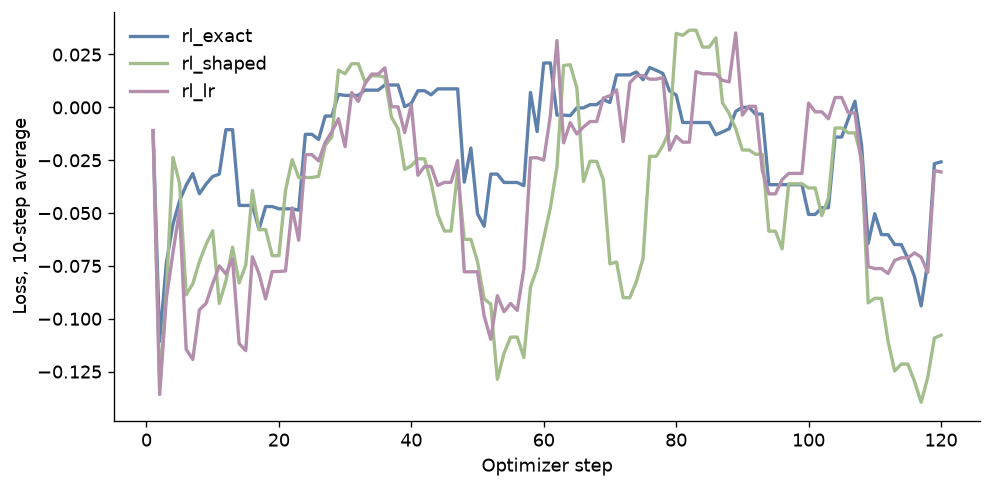

In [6]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
for name in TRAIN_RUNS:
    frame = pd.DataFrame(histories[name])
    smooth = frame["loss"].rolling(10, min_periods=1).mean()
    ax.plot(frame["step"], smooth, color=COLORS[name], linewidth=2, label=name)
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Loss, 10-step average")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PLOTS / "loss.png", dpi=160, bbox_inches="tight")
plt.show()


In [7]:
train_rows = []
for name in TRAIN_RUNS:
    steps = histories[name]
    rewards = [step["reward"] for step in steps]
    summary = read_json(ROOT / "results" / name / "summary.json")
    config = read_json(ROOT / "results" / name / "config.json")
    logged_seconds = summary.get("train_seconds")
    if logged_seconds is None:
        logged_seconds = sum(step["step_time"] for step in steps)
    train_rows.append({
        "run": name,
        "reward": "exact" if config["reward_weights"]["functions"] == 0 else "shaped",
        "learning_rate": config["learning_rate"],
        "steps": len(steps),
        "epoch_fraction": round(summary["epoch"], 4),
        "reward_first_20": round(sum(rewards[:20]) / 20, 3),
        "reward_last_20": round(sum(rewards[-20:]) / 20, 3),
        "zero_advantage_steps": summary["reward_groups"] - summary["groups_with_reward_variation"],
        "train_seconds": round(logged_seconds, 1),
        "peak_allocated_gib": round(summary["peak_allocated_gib"], 2),
    })

training = pd.DataFrame(train_rows).set_index("run")
training.to_csv(ROOT / "artifacts" / "training.csv")
training


,reward,learning_rate,steps,epoch_fraction,reward_first_20,reward_last_20,zero_advantage_steps,train_seconds,peak_allocated_gib
run,,,,,,,,,
rl_exact,exact,0.00002,120,0.0102,0.531,0.438,76,1821.6,52.10
rl_shaped,shaped,0.00002,120,0.0102,0.739,0.583,54,335.1,73.77
rl_lr,shaped,0.00001,120,0.0102,0.702,0.618,53,1645.2,51.55


## Ошибки лучшего запуска

Лучший запуск — строка с максимальным `overall`.
Счётчик показывает исправленные и испорченные ответы baseline.
Таблица ниже содержит один исправленный пример и четыре ошибки.


In [8]:
def read_predictions(name):
    rows = {}
    path = ROOT / "artifacts" / name / "predictions.jsonl"
    for line in path.read_text().splitlines():
        if line.strip():
            item = json.loads(line)
            rows[item["id"]] = item
    return rows


best_run = percent["overall"].idxmax()
baseline_predictions = read_predictions("baseline")
best_predictions = read_predictions(best_run)

flip_rows = []
for example_id, baseline_item in baseline_predictions.items():
    best_item = best_predictions[example_id]
    baseline_ok = bool(baseline_item["check"]["valid"])
    best_ok = bool(best_item["check"]["valid"])
    if baseline_ok == best_ok:
        continue
    flip_rows.append({
        "id": example_id,
        "category": baseline_item["category"],
        "baseline": baseline_ok,
        "best": best_ok,
        "change": "fixed" if best_ok else "broken",
    })

flips = pd.DataFrame(flip_rows)
flip_counts = flips.groupby(["change", "category"]).size().unstack(fill_value=0)
print(f"best run: {best_run}")
print(flips["change"].value_counts().to_string())
flip_counts


best run: rl_lr
change
fixed     7
broken    2


category,live_irrelevance,live_multiple,multiple,parallel,simple
change,,,,,
broken,1,1,0,0,0
fixed,0,0,5,1,1


In [9]:
EXAMPLE_IDS = [
    "simple_24",
    "simple_241",
    "simple_150",
    "live_multiple_793-174-7",
    "live_irrelevance_142-13-8",
]

def short_error(item):
    error = item["check"].get("error") or []
    if isinstance(error, list):
        text = "; ".join(str(part) for part in error[:2])
    else:
        text = str(error)
    return text[:180]


examples = []
for example_id in EXAMPLE_IDS:
    baseline_item = baseline_predictions[example_id]
    best_item = best_predictions[example_id]
    examples.append({
        "id": example_id,
        "category": baseline_item["category"],
        "baseline_ok": bool(baseline_item["check"]["valid"]),
        "best_ok": bool(best_item["check"]["valid"]),
        "best_calls": json.dumps(best_item["calls"], ensure_ascii=False),
        "error": short_error(best_item) or short_error(baseline_item),
    })

pd.DataFrame(examples)


,id,category,baseline_ok,best_ok,best_calls,error
0,simple_24,simple,False,True,"[{""math.gcd"": {""num1"": 12, ""num2"": 18}}]",Ожидался вызов инструмента.
1,simple_241,simple,False,False,[],Ожидался вызов инструмента.
2,simple_150,simple,False,False,"[{""calculate_roi"": {""deposit"": 1000, ""annual_i...",Invalid value for parameter 'annual_interest_r...
3,live_multiple_793-174-7,live_multiple,True,False,"[{""Homes_2_ScheduleVisit"": {""property_name"": ""...",Invalid value for parameter 'visit_date': '202...
4,live_irrelevance_142-13-8,live_irrelevance,True,False,"[{""ControlAppliance.execute"": {""command"": ""다용도...",Вызов инструмента не требовался.
